# Transit analysis of L 98-59 (TESS, SPOC 2-min cadence)

**Goal:** recover the transit depth (and from it the planet radius) of the ~3.69 d planet around L 98-59 from a TESS light curve, and compare it with the published value (fractional depth about 0.00167, radius about 1.34 Earth radii).

**Part 1** is the original pipeline: normalize, clean, flatten, fold, bin, measure depth.
**Part 2** revisits the result, shows why the first depth came out about 42% too shallow, and applies three fixes (BLS, transit-masked flatten, narrower depth window).

## 0. Setup

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
from pathlib import Path

# __file__ does not exist in a notebook, so look for the style file in the working directory
STYLE_FILE = Path.cwd() / "rose-pine-moon.mplstyle"
if STYLE_FILE.exists():
    plt.style.use(STYLE_FILE)

PERIOD = 3.690621          # orbital period in days, used for the first-pass fold

## 1. Download the data

Search MAST for the SPOC 2-minute light curves of L 98-59 and take the first sector.

In [28]:
search_lcf = lk.search_lightcurve('L 98-59', mission='TESS', author='SPOC', exptime=120)
print(search_lcf)

SearchResult containing 27 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 02 2018   SPOC     120   307210830      0.0
  1 TESS Sector 05 2018   SPOC     120   307210830      0.0
  2 TESS Sector 08 2019   SPOC     120   307210830      0.0
  3 TESS Sector 09 2019   SPOC     120   307210830      0.0
  4 TESS Sector 10 2019   SPOC     120   307210830      0.0
  5 TESS Sector 11 2019   SPOC     120   307210830      0.0
  6 TESS Sector 12 2019   SPOC     120   307210830      0.0
  7 TESS Sector 28 2020   SPOC     120   307210830      0.0
  8 TESS Sector 29 2020   SPOC     120   307210830      0.0
  9 TESS Sector 32 2020   SPOC     120   307210830      0.0
 10 TESS Sector 35 2021   SPOC     120   307210830      0.0
 11 TESS Sector 36 2021   SPOC     120   307210830      0.0
 12 TESS Sector 37 2021   SPOC     120   307210830      0

In [29]:
lc_raw = search_lcf[0].download()
lc_raw

time,flux,flux_err,timecorr,cadenceno,centroid_col,centroid_row,sap_flux,sap_flux_err,sap_bkg,sap_bkg_err,pdcsap_flux,pdcsap_flux_err,quality,psf_centr1,psf_centr1_err,psf_centr2,psf_centr2_err,mom_centr1,mom_centr1_err,mom_centr2,mom_centr2_err,pos_corr1,pos_corr2
,electron / s,electron / s,d,,pix,pix,electron / s,electron / s,electron / s,electron / s,electron / s,electron / s,,pix,pix,pix,pix,pix,pix,pix,pix,pix,pix
Time,float32,float32,float32,int32,float64,float64,float32,float32,float32,float32,float32,float32,int32,float64,float32,float64,float32,float64,float32,float64,float32,float32,float32
1354.1074113410245,2.4635420e+04,1.8856627e+01,-8.0586493e-04,91190,664.04462,338.97644,2.3127123e+04,1.7658133e+01,1.8465968e+03,5.2003989e+00,2.4635420e+04,1.8856627e+01,0,———,———,———,———,664.04462,6.2346959e-04,338.97644,6.9568102e-04,3.1294446e-02,1.5483069e-01
1354.1088002024744,2.4656008e+04,1.8861403e+01,-8.0589182e-04,91191,664.05609,338.96900,2.3150639e+04,1.7662607e+01,1.8428802e+03,5.1911125e+00,2.4656008e+04,1.8861403e+01,0,———,———,———,———,664.05609,6.2315754e-04,338.96900,6.9629494e-04,4.3172963e-02,1.4587776e-01
1354.110189063866,2.4635619e+04,1.8864876e+01,-8.0591877e-04,91192,664.07351,338.95814,2.3137189e+04,1.7665859e+01,1.8525369e+03,5.2004828e+00,2.4635619e+04,1.8864876e+01,0,———,———,———,———,664.07351,6.2400498e-04,338.95814,6.9669099e-04,6.0803384e-02,1.3428329e-01
1354.1129667867635,2.4621027e+04,1.8853863e+01,-8.0597255e-04,91194,664.05132,338.94885,2.3098303e+04,1.7655546e+01,1.8542960e+03,5.2071209e+00,2.4621027e+04,1.8853863e+01,0,———,———,———,———,664.05132,6.2639196e-04,338.94885,6.9927127e-04,3.7734102e-02,1.2694269e-01
1354.1143556482134,2.4617400e+04,1.8859161e+01,-8.0599944e-04,91195,664.09017,338.97538,2.3127893e+04,1.7660507e+01,1.8433275e+03,5.1999226e+00,2.4617400e+04,1.8859161e+01,0,———,———,———,———,664.09017,6.2417402e-04,338.97538,6.9604575e-04,7.8965843e-02,1.5301819e-01
1354.1157445097215,2.4630531e+04,1.8860582e+01,-8.0602628e-04,91196,664.08357,338.96449,2.3136076e+04,1.7661839e+01,1.8441443e+03,5.1992383e+00,2.4630531e+04,1.8860582e+01,0,———,———,———,———,664.08357,6.2411965e-04,338.96449,6.9649977e-04,7.2042428e-02,1.4030553e-01
1354.117133371171,2.4625502e+04,1.8855038e+01,-8.0605317e-04,91197,664.08138,338.96244,2.3130492e+04,1.7656647e+01,1.8393002e+03,5.1891294e+00,2.4625502e+04,1.8855038e+01,0,———,———,———,———,664.08138,6.2480610e-04,338.96244,6.9642899e-04,6.8586096e-02,1.3917884e-01
1354.118522232678,2.4619252e+04,1.8856379e+01,-8.0608000e-04,91198,664.07300,338.95776,2.3123014e+04,1.7657902e+01,1.8428878e+03,5.1969514e+00,2.4619252e+04,1.8856379e+01,0,———,———,———,———,664.07300,6.2365801e-04,338.95776,6.9719343e-04,6.0448773e-02,1.3230386e-01


## 2. Normalize and remove missing data

Dividing by the median puts the flux near 1, so a dip can be read directly as a fraction. `remove_nans` drops cadences with no measurement.

In [30]:
lc = lc_raw.normalize()
lc = lc.remove_nans()
print(len(lc), "cadences after removing NaNs")

17578 cadences after removing NaNs


## 3. SAP vs PDCSAP flux

SAP is the raw aperture photometry. PDCSAP is SAP after the pipeline removes instrumental systematics, so PDCSAP is the one used for the analysis.

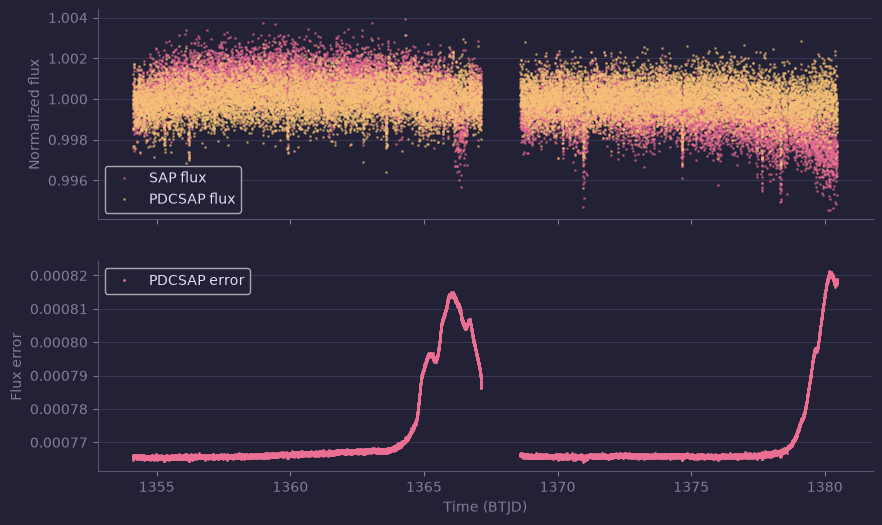

In [31]:
sap = lc.select_flux('sap_flux').normalize()
pdcsap = lc.select_flux('pdcsap_flux').normalize()

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
ax1.plot(sap.time.value, sap.flux.value, '.', markersize=2, alpha=0.5, label='SAP flux')
ax1.plot(pdcsap.time.value, pdcsap.flux.value, '.', markersize=2, alpha=0.5, label='PDCSAP flux')
ax1.set_ylabel('Normalized flux')
ax1.legend()

ax2.plot(pdcsap.time.value, pdcsap.flux_err.value, '.', markersize=2, label='PDCSAP error')
ax2.set_xlabel('Time (BTJD)')
ax2.set_ylabel('Flux error')
ax2.legend()
plt.show()

## 4. Outliers before flattening

`remove_outliers(sigma=...)` clips points more than `sigma` standard deviations from the median. Counting how many points each threshold removes helps pick a value.

In [32]:
for s in (5, 4, 3):
    _, m = lc.remove_outliers(sigma=s, return_mask=True)
    print(f"sigma = {s}: removes {m.sum()} outliers")

sigma = 5: removes 1 outliers
sigma = 4: removes 4 outliers
sigma = 3: removes 104 outliers


The star does not have many obvious outliers. Sigma = 4 removes only the most obvious points without trying to clean up ordinary noise, so that is the choice.

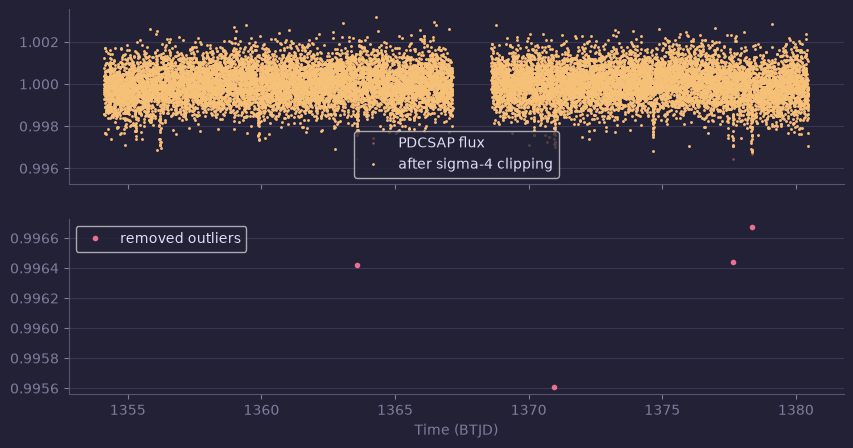

In [33]:
lc_clean, mask = lc.remove_outliers(sigma=4, return_mask=True)
outliers = lc[mask]          # the points that were removed

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.plot(lc.time.value, lc.flux.value, '.', markersize=2, alpha=0.4, label='PDCSAP flux')
ax1.plot(lc_clean.time.value, lc_clean.flux.value, '.', markersize=2, label='after sigma-4 clipping')
ax1.legend()
ax2.plot(outliers.time.value, outliers.flux.value, '.', label='removed outliers')
ax2.set_xlabel('Time (BTJD)')
ax2.legend()
plt.show()

## 5. Flatten

`flatten` fits a Savitzky-Golay filter (here a 401-cadence window, about 13 hours) and divides it out, removing slow trends so only short features such as transits remain.

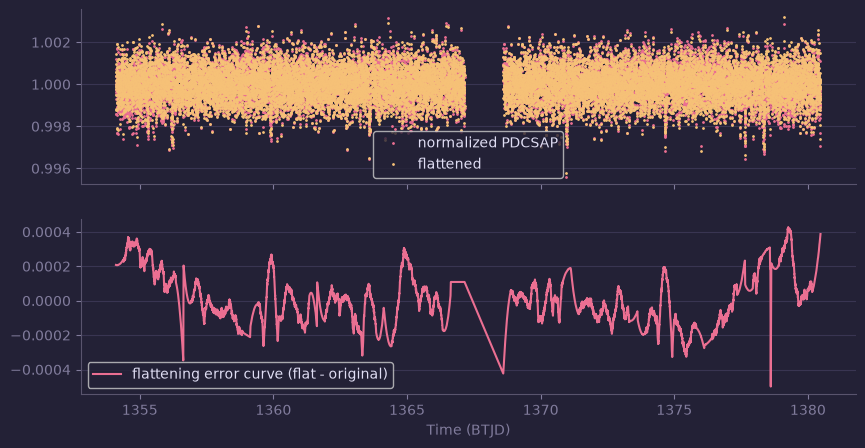

In [34]:
lc_flat = lc.flatten(window_length=401)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax1.plot(lc.time.value, lc.flux.value, '.', markersize=2, label='normalized PDCSAP')
ax1.plot(lc_flat.time.value, lc_flat.flux.value, '.', markersize=2, label='flattened')
ax1.legend()
ax2.plot(lc_flat.time.value, lc_flat.flux.value - lc.flux.value, label='flattening error curve (flat - original)')
ax2.set_xlabel('Time (BTJD)')
ax2.legend()
plt.show()

**Observation:** the error curve has an upward bowl shape, which means the original baseline had a downward bowl that flattening removed.

## 6. Outliers after flattening

Flattening changes the scatter, so the sigma choice is checked again.

In [35]:
for s in (4, 3, 2):
    _, m = lc_flat.remove_outliers(sigma=s, return_mask=True)
    print(f"sigma = {s}: removes {m.sum()} outliers")

sigma = 4: removes 3 outliers
sigma = 3: removes 101 outliers
sigma = 2: removes 2321 outliers


Sigma = 4 removes only a handful of points, consistent with the reasoning in section 4. Lower thresholds start removing ordinary noise (sigma = 2 removes thousands of points), so sigma = 4 is kept.

In [36]:
lc_clean_flat, mask = lc_flat.remove_outliers(sigma=4, return_mask=True)
print(f"removed {mask.sum()} outliers")

removed 3 outliers


## 7. Fold at the orbital period

Folding stacks every orbit on top of itself, so the transit dip adds up while random noise averages out. This needs the period, which is why the fold uses the known 3.690621 d.

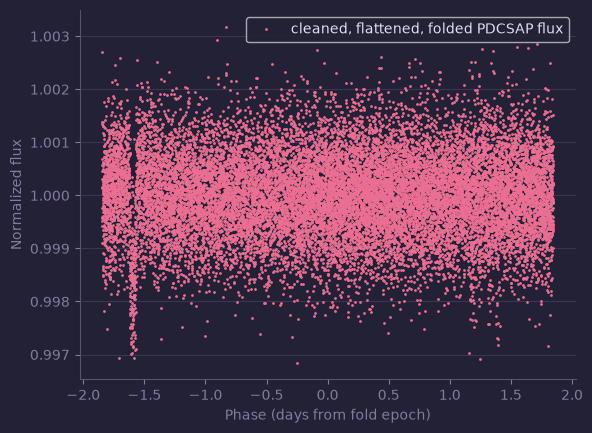

In [37]:
lc_fold = lc_clean_flat.fold(period=PERIOD)

fig, ax = plt.subplots()
ax.plot(lc_fold.time.value, lc_fold.flux.value, '.', markersize=2, label='cleaned, flattened, folded PDCSAP flux')
ax.set_xlabel('Phase (days from fold epoch)')
ax.set_ylabel('Normalized flux')
ax.legend()
plt.show()

**Observation:** there is a clear dip at around phase -1.6 d.

## 8. Bin

Averaging neighbouring points in 0.005 d bins (about 7 minutes) suppresses the scatter so the dip shape is visible.

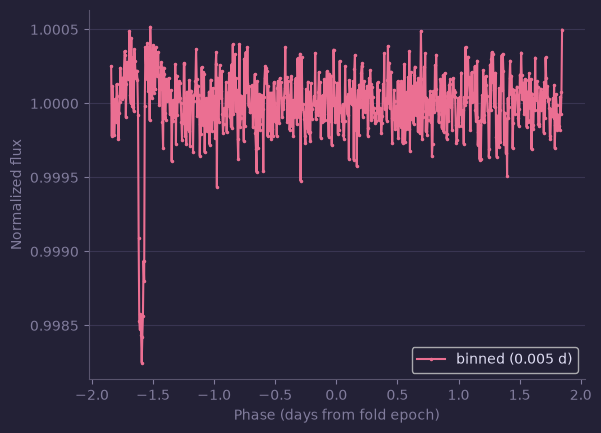

In [38]:
lc_bin = lc_fold.bin(time_bin_size=0.005)

fig, ax = plt.subplots()
ax.plot(lc_bin.time.value, lc_bin.flux.value, '.-', markersize=3, label='binned (0.005 d)')
ax.set_xlabel('Phase (days from fold epoch)')
ax.set_ylabel('Normalized flux')
ax.legend()
plt.show()

After binning, the dip is clearly visible and ready to be measured.

*Optional:* to read off phase values by clicking on the plot, run `%matplotlib widget` (needs `ipympl`) or `%matplotlib qt` before the plotting cell and add `fig.canvas.mpl_connect("button_press_event", lambda e: print(f"x={e.xdata:.5f}, y={e.ydata:.5f}") if e.inaxes else None)`.

## 9. Measure the transit by eye

Reading the ingress and egress from the binned plot (clicking on the curve):

| Point | Phase (d) |
|---|---|
| Ingress | -1.6327 |
| Mid-transit | -1.5902 |
| Egress | -1.5627 |

In [39]:
ingress, egress = -1.6327, -1.5627
duration_d = egress - ingress
print(f"transit duration = {duration_d:.3f} d = {duration_d*24*60:.0f} minutes")

transit duration = 0.070 d = 101 minutes


This gives about 0.07 d (about 101 minutes), which does not agree with the published duration. Part 2 shows why.

## 10. Transit depth from the in-transit and out-of-transit flux

The depth is the fractional drop in flux: (out-of-transit minus in-transit) divided by out-of-transit.

In [40]:
flux = lc_fold.flux.value
phase = lc_fold.time.value

in_transit  = flux[(phase > ingress) & (phase < egress)]
out_transit = flux[(phase < ingress) | (phase > egress)]

f_in, f_out = np.average(in_transit), np.average(out_transit)
depth = (f_out - f_in) / f_out
print(f"fractional transit depth = {depth:.6f}")
print(f"published depth          ~ 0.00167  -> measured is {100*(1-depth/0.00167):.0f}% shallower")

fractional transit depth = 0.000975
published depth          ~ 0.00167  -> measured is 42% shallower


**Result of Part 1:** the depth is about 0.000975 against about 0.00167 in the literature (42% shallower), which gives a radius of about 1 Earth radius against about 1.34. So something in the pipeline is diluting the signal.

## 11. Masking out edges while calculating transit flux

The fractional depth comes out shallow. To fix this, we mask out the edges of the transit, i.e. Take average only half of the points in the dip centered around the middle

In [41]:
duration = egress - ingress
in_transit  = flux[(phase > ingress + duration/4) & (phase < egress - duration/4)]
out_transit = flux[(phase < ingress) | (phase > egress)]

f_in, f_out = np.average(in_transit), np.average(out_transit)
depth = (f_out - f_in) / f_out
print(f"fractional transit depth = {depth:.6f}")
print(f"published depth          ~ 0.00167  -> measured is {100*(1-depth/0.00167):.0f}% shallower")

fractional transit depth = 0.001548
published depth          ~ 0.00167  -> measured is 7% shallower


The depth comes out to around 7% shallower, using the fractional depth to calculate radii gives

In [42]:
R_SUN_IN_R_EARTH = 109.1          # solar radius in Earth radii
R_STAR = 0.30                     # solar radii

rp_over_rs = np.sqrt(depth)
rp_over_re = rp_over_rs * R_STAR * R_SUN_IN_R_EARTH

print(f"planet radius = {rp_over_re:.2f} R_earth")

planet radius = 1.29 R_earth


## Part 2: Refining the results using specific fixes

## 12. Implementing Box Least Squares method to automatically calculate transit times and depths

we will be using astropy's BLS function to algorthmically find the periodogram and transit info of the lught curve instead of doing it manually

Period: 3.6924692469246922 d
Transit Time: 1356.1934113410246
Duration: 0.07 d
Depth: 0.0009855803291587925
Depth SNR: 0.016785227705773405
Depth is 41% shallower than published value of 0.00167


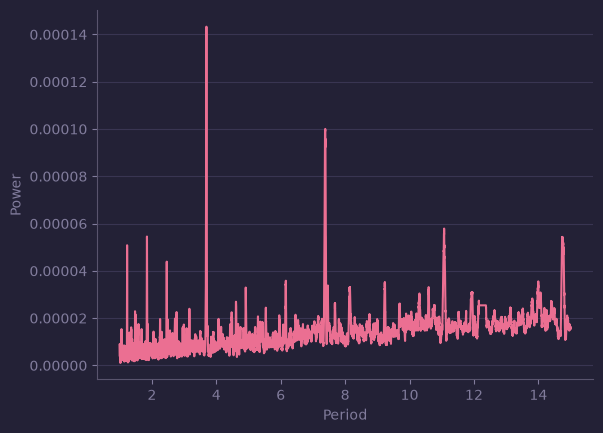

In [ ]:
import astropy.units as u
from astropy.timeseries import BoxLeastSquares

target_duration = 0.07 * u.day
bls = BoxLeastSquares(lc_clean_flat.time, lc_clean_flat.flux)

duration = 0.070 * u.day
periods = np.linspace(1, 15, 10000) * u.day
result = bls.power(periods, duration)
best = np.argmax(result.power)

print(f"Period: {result.period[best]}")
print(f"Transit Time: {result.transit_time[best]}")
print(f"Duration: {result.duration[best]}")
print(f"Depth: {result.depth[best]}")
print(f"Depth SNR: {result.depth_snr[best]}")
print(f"Depth is {100*(1-result.depth[best]/0.00167):.0f}% shallower than published value of 0.00167")

plt.plot(result.period, result.power)
plt.xlabel("Period")
plt.ylabel("Power")
plt.savefig("periodogram.png", dpi=300)
plt.show()


The periodogram shows a clears spikes of periods around 3.69 days (the planet we are targetting) and 7.45 days, however it still calculates the depth to be 41% shallower,
this is because we still havent masked the edges while calculating flux.

baseline flux = 1.000010
transit flux = 0.998492
fractional transit depth = 0.001518
published depth          ~ 0.00167  -> measured is 9% shallower


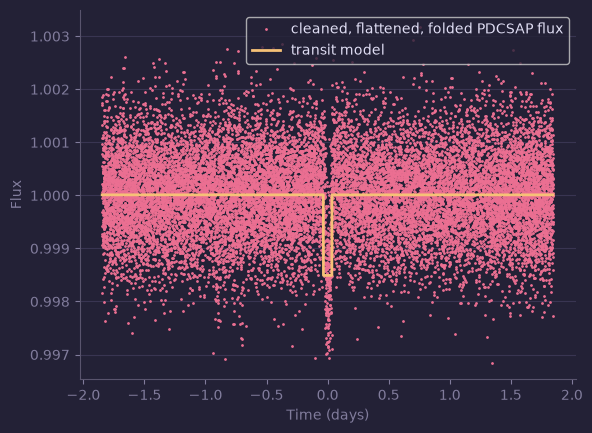

In [ ]:
transit_time = result.transit_time[best].value
transit_duration = result.duration[best].value

transit_start = transit_time - transit_duration/2
transit_end = transit_time + transit_duration/2

lc_fold_bls = lc_clean_flat.fold(period=result.period[best], epoch_time=transit_time)
baseline = np.mean(lc_fold_bls.flux.value[(lc_fold_bls.time.value < - (3/4) * transit_duration) | (lc_fold_bls.time.value > (3/4) * transit_duration)])
transit_flux = np.mean(lc_fold_bls.flux.value[(lc_fold_bls.time.value > - (1/4) * transit_duration) & (lc_fold_bls.time.value < (1/4) * transit_duration)])

print(f"baseline flux = {baseline:.6f}")
print(f"transit flux = {transit_flux:.6f}")
print(f"fractional transit depth = {(baseline - transit_flux) / baseline:.6f}")
print(f"published depth          ~ 0.00167  -> measured is {100*(1-(baseline - transit_flux) / baseline/0.00167):.0f}% shallower")

box = np.where((lc_fold_bls.time.value > - transit_duration / 2) & (lc_fold_bls.time.value < transit_duration / 2), transit_flux, baseline)

plt.plot(lc_fold_bls.time.value, lc_fold_bls.flux.value, '.', markersize=2, label='cleaned, flattened, folded PDCSAP flux')
plt.plot(lc_fold_bls.time.value, box, '-', linewidth=2, label='transit model')
plt.xlabel('Time (days)')
plt.ylabel('Flux')
plt.legend()
plt.savefig("transit_model.png", dpi=300)
plt.show()


This plot shows how our model fits over the folded lightcurve